In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv

In [2]:
class BlogState(TypedDict):

    title : str
    outline: str
    content: str

In [3]:
model = ChatOpenAI(model_name="gpt-4.1-nano", temperature=0.2)

In [4]:
def createOutline(state: BlogState) -> BlogState:
    #fetch title
    title = state['title']
    # call llm to gen outline
    prompt = f'Generate a detailed outline for a blog on the topic-{title}'
    outline = model.invoke(prompt)

    # update state
    state['outline'] = outline

    return state

In [5]:
def createBlog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Right a detailed blog on the {title}  using the following {outline}'

    content = model.invoke(prompt)

    state['content'] = content

    return state


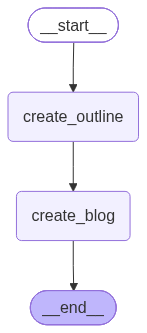

In [6]:
graph = StateGraph(BlogState)

# nodes
graph.add_node('create_outline', createOutline)
graph.add_node('create_blog', createBlog)

# Edges

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

graph.compile()

In [7]:
workflow = graph.compile()

In [8]:
intState = {'title': 'Rise of AI in India'}

finalState = workflow.invoke(intState)

print(finalState)

{'title': 'Rise of AI in India', 'outline': AIMessage(content='**Blog Title: The Rise of AI in India: Transforming the Nation’s Future**\n\n---\n\n### I. Introduction\n- Brief overview of Artificial Intelligence (AI) and its global significance\n- The emergence of AI in India: a transformative journey\n- Purpose and scope of the blog\n\n### II. Historical Context and Evolution of AI in India\n- Early developments in AI research and initiatives\n- Key milestones in India’s AI landscape\n- Government policies and strategic initiatives (e.g., NITI Aayog’s National Strategy for AI)\n\n### III. Factors Driving the Rise of AI in India\n- Demographic dividend: a young, tech-savvy population\n- Growing digital infrastructure and internet penetration\n- Increasing investments from government and private sector\n- Availability of vast data sources and digital footprints\n- Academic and research institutions contributing to AI innovation\n\n### IV. Key Sectors Transformed by AI in India\n#### A. 

In [9]:
print(finalState['content'])

content='**Blog Title: The Rise of AI in India: Transforming the Nation’s Future**\n\n---\n\n### I. Introduction\n\nArtificial Intelligence (AI) has emerged as a revolutionary force transforming industries, economies, and societies worldwide. Globally, AI is driving innovation in healthcare, finance, transportation, and more, promising increased efficiency, personalized experiences, and solutions to complex problems. India, with its unique demographic and economic landscape, is rapidly embracing AI, positioning itself as a significant player in the global AI ecosystem.\n\nThe journey of AI in India is marked by remarkable progress, strategic initiatives, and a vision to leverage technology for inclusive growth. This blog explores the evolution, current landscape, challenges, and future prospects of AI in India, highlighting how this transformative technology is shaping the nation’s future.\n\n---\n\n### II. Historical Context and Evolution of AI in India\n\nIndia’s engagement with AI d